# MC2: Mustererkennung in einer Schweizer QR-Rechnung

**Student:** Haris Salii  
**Land:** Schweiz  
**Semester:** HS26  
**Gewählte Aufgabe:** Klassische Mustererkennung (Tag 6–10)  
**Algorithmus:** Canny-Kantendetektor



## Tag 6: Technische Umsetzung

Der Canny-Kantendetektor wird als explizite Abfolge einzelner Verarbeitungsschritte umgesetzt. Ein einfaches geometrisches Testbild dient ausschliesslich dazu, die korrekte Funktionsweise zu überprüfen. An diesem Tag werden noch kein anwendungsspezifischer Use Case und keine quantitative Evaluation eingeführt.

In [1]:
import base64
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter

plt.rcParams["figure.dpi"] = 110

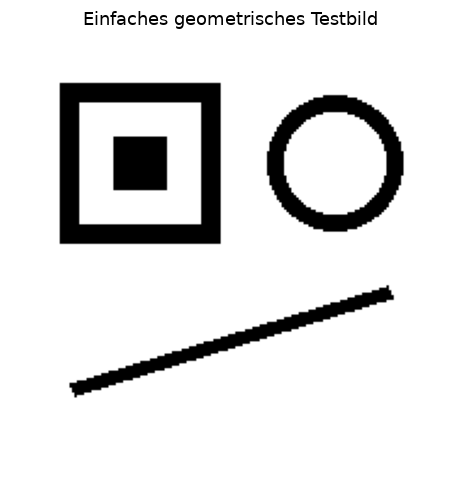

In [2]:
# Einfaches Testbild mit unterschiedlichen geometrischen Begrenzungen
test_image_pil = Image.new("L", (180, 180), color=255)
draw = ImageDraw.Draw(test_image_pil)
draw.rectangle((20, 20, 85, 85), outline=0, width=8)
draw.rectangle((42, 42, 63, 63), fill=0)
draw.ellipse((105, 25, 160, 80), outline=0, width=7)
draw.line((25, 145, 155, 105), fill=0, width=6)
test_image = np.asarray(test_image_pil, dtype=np.uint8)

plt.figure(figsize=(4.5, 4.5))
plt.imshow(test_image, cmap="gray", vmin=0, vmax=255)
plt.title("Einfaches geometrisches Testbild")
plt.axis("off")
plt.tight_layout()

### Explizite Schritte des Algorithmus

1. Die gaußsche Glättung reduziert kleine Intensitätsschwankungen.
2. Sobel-Filter berechnen die horizontalen und vertikalen Gradienten.
3. Gradientenstärke und -richtung beschreiben Stärke und Orientierung jedes lokalen Helligkeitsübergangs.
4. Die Non-Maximum Suppression behält nur lokale Maxima entlang der Gradientenrichtung.
5. Die doppelte Schwellenwertbildung trennt starke und schwache Kantenkandidaten.
6. Die Hysterese behält schwache Kandidaten nur, wenn sie mit einer starken Kante verbunden sind.

In [3]:
SOBEL_X = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype=float)
SOBEL_Y = SOBEL_X.T


def gaussian_smoothing(image, sigma):
    image_8bit = np.asarray(image, dtype=np.uint8)
    blurred = Image.fromarray(image_8bit).filter(ImageFilter.GaussianBlur(radius=sigma))
    return np.asarray(blurred, dtype=float)


def convolve_3x3(image, kernel):
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    height, width = image.shape
    padded = np.pad(image, 1, mode="reflect")
    result = np.zeros_like(image, dtype=float)
    for row in range(3):
        for column in range(3):
            result += kernel[row, column] * padded[row:row + height, column:column + width]
    return result


def non_maximum_suppression(magnitude, direction):
    suppressed = np.zeros_like(magnitude)
    direction_degrees = (np.rad2deg(direction) + 180) % 180

    center = magnitude[1:-1, 1:-1]
    angles = direction_degrees[1:-1, 1:-1]
    output = suppressed[1:-1, 1:-1]

    comparisons = [
        ((angles < 22.5) | (angles >= 157.5), magnitude[1:-1, :-2], magnitude[1:-1, 2:]),
        ((angles >= 22.5) & (angles < 67.5), magnitude[:-2, 2:], magnitude[2:, :-2]),
        ((angles >= 67.5) & (angles < 112.5), magnitude[:-2, 1:-1], magnitude[2:, 1:-1]),
        ((angles >= 112.5) & (angles < 157.5), magnitude[:-2, :-2], magnitude[2:, 2:]),
    ]

    for direction_mask, neighbour_1, neighbour_2 in comparisons:
        keep = direction_mask & (center >= neighbour_1) & (center >= neighbour_2)
        output[keep] = center[keep]
    return suppressed


def dilate_binary(mask):
    mask = np.asarray(mask, dtype=bool)
    height, width = mask.shape
    padded = np.pad(mask, 1, mode="constant", constant_values=False)
    dilated = np.zeros_like(mask)
    for row in range(3):
        for column in range(3):
            dilated |= padded[row:row + height, column:column + width]
    return dilated


def double_threshold_and_hysteresis(suppressed, low_threshold, high_threshold):
    maximum = suppressed.max()
    normalized = suppressed / maximum if maximum > 0 else suppressed.copy()

    strong = normalized >= high_threshold
    weak = (normalized >= low_threshold) & ~strong
    edges = strong.copy()
    remaining_weak = weak.copy()

    while True:
        connected = remaining_weak & dilate_binary(edges)
        if not connected.any():
            break
        edges |= connected
        remaining_weak &= ~connected

    return edges, normalized, strong, weak


def canny_steps(image, sigma, low_threshold, high_threshold):
    smoothed = gaussian_smoothing(image, sigma)
    gradient_x = convolve_3x3(smoothed, SOBEL_X)
    gradient_y = convolve_3x3(smoothed, SOBEL_Y)
    magnitude = np.hypot(gradient_x, gradient_y)
    direction = np.arctan2(gradient_y, gradient_x)
    suppressed = non_maximum_suppression(magnitude, direction)
    edges, normalized, strong, weak = double_threshold_and_hysteresis(
        suppressed, low_threshold, high_threshold
    )
    return {
        "smoothed": smoothed,
        "gradient_x": gradient_x,
        "gradient_y": gradient_y,
        "magnitude": magnitude,
        "direction": direction,
        "suppressed": suppressed,
        "normalized": normalized,
        "strong": strong,
        "weak": weak,
        "edges": edges,
    }


In [4]:
# Parameter nur für die Funktionskontrolle
test_sigma = 1.0
test_low_threshold = 0.20
test_high_threshold = 0.40

test_result = canny_steps(
    test_image,
    sigma=test_sigma,
    low_threshold=test_low_threshold,
    high_threshold=test_high_threshold,
)

print(f"Gauß-Sigma: {test_sigma}")
print(f"Unterer Schwellenwert: {test_low_threshold}")
print(f"Oberer Schwellenwert: {test_high_threshold}")
print(f"Form des Eingabebildes: {test_image.shape}")
print(f"Form des Ergebnisbildes: {test_result['edges'].shape}")

Gauß-Sigma: 1.0
Unterer Schwellenwert: 0.2
Oberer Schwellenwert: 0.4
Form des Eingabebildes: (180, 180)
Form des Ergebnisbildes: (180, 180)


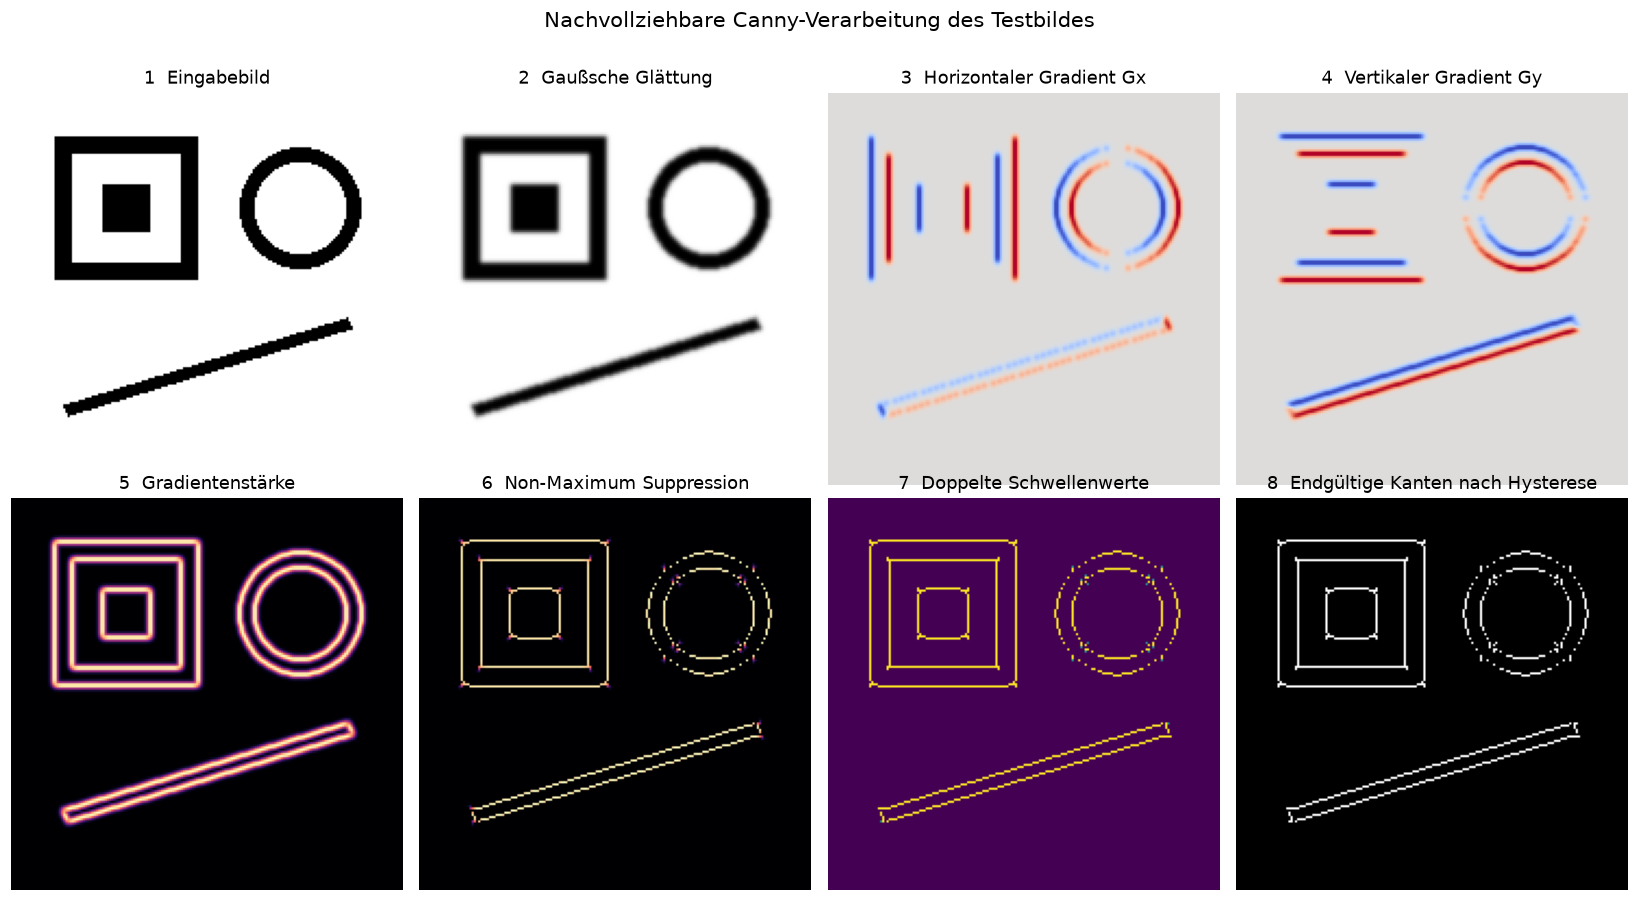

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

visualizations = [
    (test_image, "1  Eingabebild", "gray"),
    (test_result["smoothed"], "2  Gaußsche Glättung", "gray"),
    (test_result["gradient_x"], "3  Horizontaler Gradient Gx", "coolwarm"),
    (test_result["gradient_y"], "4  Vertikaler Gradient Gy", "coolwarm"),
    (test_result["magnitude"], "5  Gradientenstärke", "magma"),
    (test_result["suppressed"], "6  Non-Maximum Suppression", "magma"),
    (test_result["strong"].astype(int) + 0.5 * test_result["weak"].astype(int),
     "7  Doppelte Schwellenwerte", "viridis"),
    (test_result["edges"], "8  Endgültige Kanten nach Hysterese", "gray"),
]

for axis, (image, title, color_map) in zip(axes.ravel(), visualizations):
    axis.imshow(image, cmap=color_map)
    axis.set_title(title)
    axis.axis("off")

fig.suptitle("Nachvollziehbare Canny-Verarbeitung des Testbildes", y=1.02, fontsize=14)
fig.tight_layout()


**Funktionskontrolle:** Die Bildgrösse bleibt während der gesamten Verarbeitung unverändert. Die horizontalen und vertikalen Sobel-Ergebnisse reagieren auf unterschiedliche Kantenrichtungen. Die Non-Maximum Suppression verdünnt die breiten Gradientenreaktionen, und die Hysterese erzeugt zusammenhängende, ungefähr ein Pixel breite Kantenkonturen um die geometrischen Objekte. Damit ist der vorgesehene Aufbau der Implementierung überprüft, ohne bereits die Leistung im späteren Anwendungsfall zu bewerten.

## Day 7: Methodological Design

### Theoretical Foundation and Method Choice
*Focus: principled justification aligned with the use case*

<span style="background-color: #eeeeee;">*Guidelines: Establish the governing theoretical principle underlying your selected signal or image processing operation and briefly justify your chosen 1-2 method(s) in direct relation to your previously defined country-specific use case. State the key assumptions and validity conditions of the theory, and explain why the selected method appropriately operationalizes this principle for your data characteristics and analytical objective. Keep the explanation concise and technically precise. 2-4 sentences.*</span>

You may use the following structure as guidance:

> This investigation applies the principle of ____________ to ____________ within the context of ____________ [use case, selected country].
This principle assumes ____________ and is valid under ____________.
The method ____________ is selected because it appropriately models / estimates / transforms ____________.
If these assumptions are violated, ____________ may occur, compromising ____________ in [this application, use case].

### Parameter Definition and Mathematical Specification
*Focus: explicit parameter selection, derivation, and unit consistency*

<span style="background-color: #eeeeee;">*Guidelines: Define and justify relevant signal/image parameters and method-specific parameters required for your analysis. Clearly distinguish between data-inherent parameters (e.g., sampling frequency, spatial resolution, signal length, bandwidth) and method parameters (e.g., kernel size, lag range, cutoff frequency, window length). Derive necessary quantities mathematically where applicable and document each step with explicit assumptions and consistent physical units. Explicitly map abstract parameters to their physical meaning in your domain (e.g., lag in days, kernel width in meters or pixels). Parameter choices must be technically motivated and aligned with the defined use case. 2-4 sentences.*</span>

You may use the following structure as guidance:

> The signal/image is characterized by ____________ [properties and units].
Based on the theoretical principle, the following parameters are required: ____________.
The value of ____________ is derived as ____________ [include units], assuming ____________.
In this domain, ____________ corresponds to ____________ [physical interpretation].
These parameter choices are appropriate because ____________ in the context of ____________.

### Experimental Design for Next Days
*Focus: structured parameter variation and theoretical prediction*

<span style="background-color: #eeeeee;">*Guidelines: Specify the experimental setup to be implemented on the next days. Define the baseline configuration and identify the key 2-4 parameters that will be systematically varied. Describe the structured parameter sweep (ranges, step sizes, and controlled variables) and justify why these variations are meaningful for your signal or image and use case. Theoretically predict the expected qualitative effects of parameter changes. Ensure the setup is traceable and reproducible by clearly documenting fixed settings and variation logic. Theoretically predict the expected qualitative effects of these parameter changes on signal behavior, image structure, or system response. No simulations or results should be included. 2-4 sentences.*</span>

You may use the following structure as guidance:

> The baseline configuration is defined as ____________.
The following parameters will be varied systematically: ____________.
The selected range ____________ is justified because ____________.
It is theoretically expected that increasing/decreasing ____________ will lead to ____________ since ____________.
All configurations will be documented to ensure traceability.

### Methodological Limitations and Risk Factors
*Focus: assumptions, stability, and potential misinterpretation*

<span style="background-color: #eeeeee;">*Guidelines: Identify the main methodological 1-3 limitations of your theoretical model, method selection, and parameterization. Explicitly state idealized assumptions and discuss how real-world signal or image characteristics may violate them (e.g., noise, non-linearity, non-stationarity, boundary effects, model mismatch, limited resolution). Analyze under which conditions the method remains stable and valid, and under which conditions it may become unreliable or misleading in your use case. 1-3 sentences.*</span>

You may use the following structure as guidance:

> This approach assumes ____________, which may be violated if ____________ in the selected data.
> The method is expected to be reliable when ____________, but may become unstable or misleading when ____________.
In this  ____________ [use case, application], the primary risk factors are ____________, potentially leading to ____________.

## Day [3, 8, 13] – Implementation

*Focus: structured, traceable execution*

<span style="background-color: #eeeeee;">*Guidelines: Implement the previously defined methodological framework in a structured and reproducible manner. Organize your notebook clearly, separating data preparation, parameter definition, baseline configuration, and parameter variation. The implementation must directly follow the previously defined methodological plan. All relevant parameters must be explicitly declared and applied as specified. Do not introduce new methods or undocumented parameter changes; any deviation must be briefly justified (one sentence).
Ensure that each experiment is traceable by clearly labeling configurations and avoiding undocumented changes. Visualizations must include properly labeled axes (with units where applicable), clear legends, and consistent formatting to allow comparison across parameter settings.
 If not otherwise stated, libarys may be used for your implementations. Keep experiments concise and focused. Observations, interpretation and performance evaluation will be conducted on a later day.*</span>

<span style="background-color: #eeeeee;">*Code Quality Requirements: The submission must not contain any commented-out code passages. Code should be clean, readable, and executable without residual development artifacts. Comments should be used sparingly and only where they add value. In particular, comments are appropriate when explaining why a specific methodological decision was made, clarifying non-obvious implementation details, or referencing a theoretical source. Avoid redundant comments that merely restate what the code already expresses.
The code should be written in a clear and structured manner such that its logic is largely self-explanatory. Use meaningful variable names and consistent formatting to enhance readability.*</span>

## Day [4, 9, 14] – Evaluation

*Focus: systematic, traceable evaluation of the predefined experiment design and its key parameters.*

<span style="background-color: #eeeeee;">*Systematically evaluate the predefined experiment design in relation to the defined use case. The evaluation must be traceable, structured, and based on consistent criteria. All reported metrics or extracted quantities must include appropriate physical units or clearly indicate normalization to ensure consistent and meaningful comparison. The same predefined evaluation approach must be applied consistently across all experiments and parameter configurations to maintain traceability and comparability. No new simulations, theoretical derivations, or interpretative discussion should be introduced.*</span>

### Evaluation Approach Definition

<span style="background-color: #eeeeee;">*Guidelines: Define 1–2 quantitative evaluation approaches, which may consist of numerical metrics and/or quantitatively interpretable visualizations. Justify why the selected approach is appropriate for your signal or image characteristics and application objective, and clearly specify what aspect of performance it captures (e.g., fidelity, detection accuracy, reconstruction quality, robustness, distortion). Visualizations must include labeled axes with units and enable measurable comparison across configurations. 2-3 sentences.*</span>

You may use the following structures as guidance, depending on whether your evaluation approach is metric-based or visualization-based.

#### Template – Metric-Based Evaluation

> The selected metric is __________, which quantifies ____________ in relation to [the defined use case].
It is specifically chosen because the problem statement requires accurate assessment of ____________, and this metric directly reflects changes in ____________.
The validity of this metric depends on ____________, which must hold for the evaluation to be meaningful in this application.

Example – Root Mean Squared Error (RMSE):

> The selected metric is RMSE, which quantifies the deviation between the reconstructed signal and the high-resolution reference. It is specifically chosen because [the use case] requires accurate amplitude reconstruction over time, and RMSE directly reflects reconstruction fidelity. The metric is meaningful here because a validated reference signal is available and serves as ground truth.

#### Template – Visualization-Based Evaluation

> The evaluation uses a __________ visualization, representing ____________ with clearly labeled axes and units.
The evaluated quantity is ____________, which is directly relevant to [the defined use case] because the problem requires reliable assessment of ____________.
This approach is appropriate under ____________, ensuring that the extracted feature meaningfully reflects performance in this application context.

Example – Frequency Spectrum Comparison:

> The evaluation uses a frequency spectrum visualization to assess whether dominant periodic components are preserved. The evaluated quantity is the measurable peak frequency and its amplitude, which are directly relevant because the use case requires reliable detection of periodic behavior. This approach is appropriate since frequency preservation is more critical than pointwise amplitude accuracy in this application.

### Evaluation Comparison Execution

<span style="background-color: #eeeeee;">*Guidelines: Apply the defined evaluation approach consistently across all predefined experiments or configurations. Systematically vary 2–4 previously defined key parameters and quantify their influence on performance relative to a clearly specified baseline configuration. Results must be reported in a structured format (e.g., tables or measurable graphics) to ensure traceability. 2-4 sentences.*</span>


#### Template – Parameter Evaluation (Metric-Based)

>The influence of key parameters __________ was evaluated using the previously defined metric __________.
These parameters are essential for [the defined use case] because they directly affect ____________, which is critical for ____________.
Changes in __________ [metric] across parameter settings quantify how sensitive the experiment design is to ____________.
Relative performance change was computed with respect to the baseline configuration ____________.

#### Template – Parameter Evaluation (Visualization-Based)

>The influence of key parameters __________ was evaluated using the previously defined visualization-based measure __________.
These parameters are essential for the defined use case because they influence ____________, which determines ____________ in [the application context].
Differences in the extracted quantity __________ across parameter settings quantify the impact of ____________ on performance.
Relative performance change was computed with respect to the baseline configuration ____________.

In [6]:
## Placeholder for code-based analysis, quantitative result reporting, and structured comparison using tables and/or graphics.

Example universal comparison table:

| Experiment / Configuration        | Metric / Quantity 1 | Metric / Quantity 2 (optional) | Relative Change to Baseline (%) |
|:----------------------------------|:--------------------|:--------------------------------|:--------------------------------|
| Baseline: ____________            |                     |                                  | 0%                               |
| Configuration 1: ____________     |                     |                                  |                                  |
| Configuration 2: ____________     |                     |                                  |                                  |
| Configuration 3: ____________     |                     |                                  |                                  |


Example for Sampling Rate Variation:


| Experiment / Configuration | RMSE | Relative Change to Baseline (%) |
|:----------------------------|:-----|:--------------------------------|
| Baseline: Fs = 100 Hz      | 0.12 | 0%                               |
| Fs = 50 Hz                 | 0.18 | +50%                             |
| Fs = 25 Hz                 | 0.45 | +275%                            |

## Day [5, 10, 15] – Analysis & Communication

*Focus: Analytical Interpretation and Domain-Specific Discussion*

<span style="background-color: #eeeeee;">*Guidelines: Based on the quantitative evaluation from the Evaluation day, critically analyze your findings in direct relation to your defined use case and selected signal or image. Structure your analysis into (1) observations, (2) interpretation, and (3) discussion. Observations must reference concrete quantitative results; interpretations must explain domain-specific implications; the discussion must critically assess the practical applicability, limitations, and risks of your implementation and evaluation approach. All arguments must explicitly connect to the original problem statement and use case. No new simulations or derivations may be introduced.*</span>

### Observations (3-5 sentences)
Focus: Describe measurable results only — no explanation.

> The quantitative evaluation shows that ____________ changes from ____________ to ____________ across configurations ____________.
The defined metric / extracted quantity indicates that ____________.
Performance differences are most pronounced when ____________.

### Interpretation (3-5 sentences)
Focus: Explain what the results mean for the application.

>In the context of ____________ [use case], these results imply that ____________.
The observed variation in ____________ affects ____________ because ____________.
This suggests that ____________ is particularly critical for achieving the objective defined in the problem statement.


### Discussion and Critical Reflection (4–6 sentences)
*Focus: Relate the quantitative findings to the requirements of the defined use case and assess practical adequacy.*

> For the defined use case, the configurations ____________ performed well because they achieved ____________, which aligns with the requirement of ____________.
In contrast, configurations ____________ showed reduced performance, leading to ____________ and limiting their suitability for this application.
The achieved performance level can be considered sufficient / insufficient for the use case because ____________.
The implementation and evaluation approach assumes ____________, which may be constrained under real-world conditions such as ____________.
To improve robustness or applicability, future work should address ____________ or refine ____________.

## Day 15 

### Final Reflections on MC
>Overall, the most successful aspect of MC1 was ____________, particularly in relation to ____________ within the defined use case. The implementation of ____________ worked well because ____________, leading to ____________.
If repeating this work, I would reconsider ____________ or refine ____________, as this could improve ____________ and reduce ____________. Certain challenges emerged during ____________, highlighting the importance of ____________ in practical signal/image analysis.
I was particularly impressed by ____________, especially how ____________ influenced ____________ in the context of the application.
Through this project, I learned that ____________, and I developed a clearer understanding of ____________, especially regarding the connection between theoretical principles and real-world constraints.

### Revisions
<span style="background-color: #fff3b0;"><strong>Template for Revisions:</strong> [your changes... ]</span>